In [0]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 1500

areas = ["Fiscal", "Faturamento", "Logística", "Compras", "Facilities", "TI"]
area_p = [0.18, 0.17, 0.20, 0.15, 0.12, 0.18]
categorias = ["Documento Fiscal", "Cadastro", "Requisição", "Suporte Sistema", "Logística", "Contrato"]
cat_p = [0.22, 0.16, 0.18, 0.17, 0.15, 0.12]
prioridades = ["Alta", "Média", "Baixa"]
prio_p = [0.25, 0.50, 0.25]

sla_map = {"Alta": 24, "Média": 48, "Baixa": 72}
media_area = {"Fiscal": 14, "Faturamento": 12, "Logística": 18, "Compras": 25, "Facilities": 16, "TI": 10}
fator_categoria = {"Documento Fiscal": 1.00, "Cadastro": 1.25, "Requisição": 1.15, "Suporte Sistema": 1.35, "Logística": 1.05, "Contrato": 1.10}
fator_prioridade = {"Alta": 0.80, "Média": 1.00, "Baixa": 1.30}

data_corte = pd.Timestamp("2026-10-31 18:00")

abertura = pd.Timestamp("2026-01-01") + pd.to_timedelta(rng.integers(0, 300 * 24 * 60, n), unit="m")

df = pd.DataFrame({
    "id_chamado": [f"CH-{i:05d}" for i in range(1, n + 1)],
    "data_abertura": abertura,
    "area": rng.choice(areas, n, p=area_p),
    "categoria": rng.choice(categorias, n, p=cat_p),
    "prioridade": rng.choice(prioridades, n, p=prio_p),
})

df["sla_horas"] = df["prioridade"].map(sla_map)

media = (
    df["area"].map(media_area)
    * df["categoria"].map(fator_categoria)
    * df["prioridade"].map(fator_prioridade)
)
df["tempo_atendimento_horas"] = np.round(rng.lognormal(np.log(media), 0.45), 1)

em_andamento = rng.random(n) < 0.08
df["data_conclusao"] = df["data_abertura"] + pd.to_timedelta(df["tempo_atendimento_horas"], unit="h")
df.loc[em_andamento, "data_conclusao"] = pd.NaT
df.loc[em_andamento, "tempo_atendimento_horas"] = np.nan
df["status"] = np.where(em_andamento, "Em andamento", "Concluído")

horas_decorridas = (data_corte - df["data_abertura"]).dt.total_seconds() / 3600
df["sla_status"] = np.select(
    [
        df["status"].eq("Concluído") & (df["tempo_atendimento_horas"] <= df["sla_horas"]),
        df["status"].eq("Concluído"),
        horas_decorridas > df["sla_horas"],
    ],
    ["Cumprido", "Vencido", "Vencido"],
    default="No prazo",
)

df = df[["id_chamado", "data_abertura", "data_conclusao", "area", "categoria",
         "prioridade", "sla_horas", "tempo_atendimento_horas", "status", "sla_status"]]

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


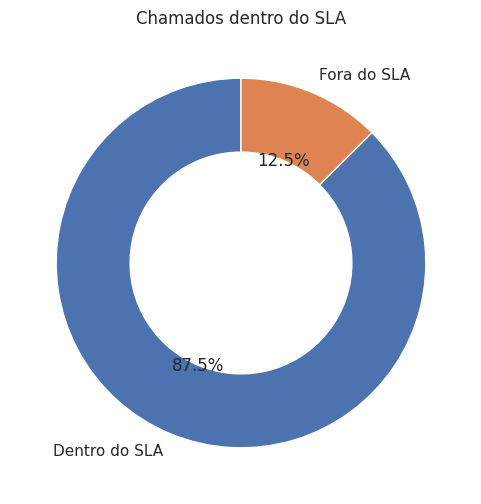

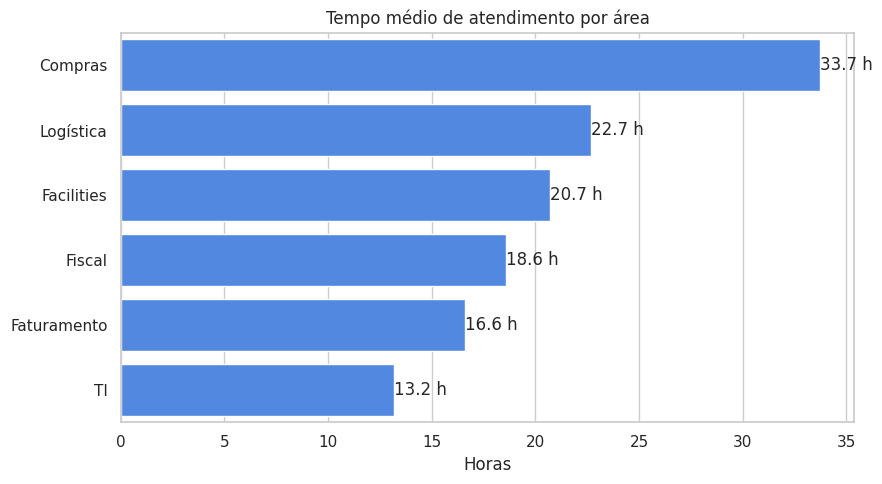

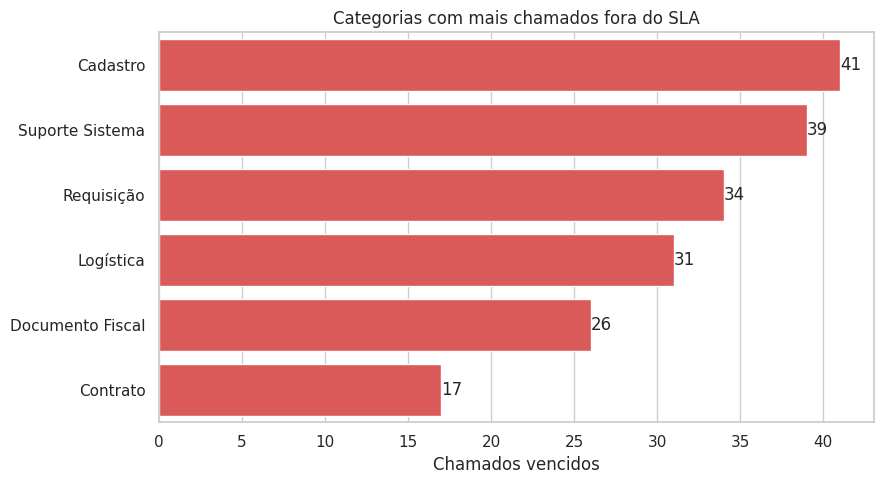

In [0]:
%pip install seaborn

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

dentro = (df["sla_status"] != "Vencido").mean() * 100
fora = 100 - dentro

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    [dentro, fora],
    labels=["Dentro do SLA", "Fora do SLA"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4},
)
ax.set_title("Chamados dentro do SLA")
plt.show()

tempo_area = (
    df[df["status"] == "Concluído"]
    .groupby("area")["tempo_atendimento_horas"]
    .mean()
    .round(1)
    .sort_values(ascending=False)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=tempo_area, x="tempo_atendimento_horas", y="area", ax=ax, color="#3B82F6")
ax.set_title("Tempo médio de atendimento por área")
ax.set_xlabel("Horas")
ax.set_ylabel("")
ax.bar_label(ax.containers[0], fmt="%.1f h")
plt.tight_layout()
plt.show()

atrasos = (
    df[df["sla_status"] == "Vencido"]
    .groupby("categoria")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="chamados_vencidos")
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=atrasos, x="chamados_vencidos", y="categoria", ax=ax, color="#EF4444")
ax.set_title("Categorias com mais chamados fora do SLA")
ax.set_xlabel("Chamados vencidos")
ax.set_ylabel("")
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

In [0]:
spark.createDataFrame(df).write.mode("overwrite").saveAsTable("sla_chamados")